# Kdy letět s termokamerou, pokročilá verze: svahy, stíny a les na skutečném terénu

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/thermal_timing_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kdy letět s termokamerou](https://openskylab.space/edu_viz_thermal_timing.html) · [English version](thermal_timing_pro_en.ipynb)

Pokročilá verze notebooku o načasování termálního snímkování. Model povrchu ze základní verze tu běží pro každou čtyřmetrovou buňku skutečného svahu údolí Vltavy u Roztok: se sklonem a orientací z DMR 5G, se stíny terénu, s rozlišením lesa a louky z DMP 1G a se skutečným přímým a rozptýleným zářením z Open-Meteo. Zjistíš, kdy samotný terén vytváří v termosnímku největší a nejmenší rozdíly a kdy se les a louka teplotně překříží.

**Cíl:** spočítat polohu Slunce, osvit svahů a stíny terénu, spustit energetickou bilanci povrchu pro každou buňku území, porovnat teplotu luk podle orientace svahu během dne a najít denní dobu, kdy je teplota nejméně ovlivněná terénem, ve slunečném i zataženém dni.

**Data:** DMR 5G (terén) a DMP 1G (povrch) z ČÚZK, buňka 4 m, území 1 × 0,7 km na levém svahu údolí Vltavy u Roztok; hodinová teplota, vlhkost, přímé (na kolmou plochu) a rozptýlené záření, oblačnost a vítr z Open-Meteo za posledních 92 dní (model počasí, ne měření na místě); tepelné vlastnosti louky a lesa stejné jako v základní verzi. Model nepočítá se stékáním studeného vzduchu do údolí v noci, s odraženým zářením z okolních svahů ani s vlhkostí půdy, která se mění; DMP 1G je z let 2009–2013.

**Úkoly:** čtyři. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 55 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava, terén a počasí

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

terén 175–252 m n. m., les na 79% území, sklon až 55°


nejslunečnější den 2026-08-07 (7.0 kWh/m²), nejzataženější 2026-10-25 (0.4 kWh/m²)


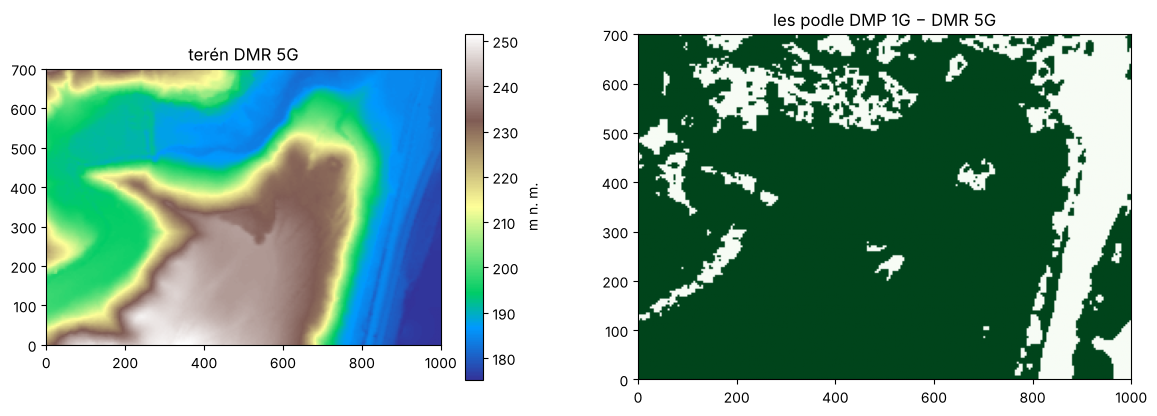

In [3]:
LAT, LON = 50.152, 14.392           # ◀ parametr: střed území (levý svah údolí Vltavy u Roztok)
W, Hh, RES = 1000, 700, 4.0         # šířka a výška území (m), buňka 4 m
FOREST_H = 5.0                      # ◀ parametr: od jaké výšky vegetace (m) počítáme buňku jako les
cx, cy = Transformer.from_crs(4326, 5514, always_xy=True).transform(LON, LAT)
box = (cx - W / 2, cy - Hh / 2, cx + W / 2, cy + Hh / 2)
dmr, _ = cuzk_raster("dmr5g", *box, res=RES)
dmp, _ = cuzk_raster("dmp1g", *box, res=RES)
forest = (dmp - dmr) > FOREST_H
gy, gx = np.gradient(dmr, RES)                         # řádky jdou k jihu
slope = np.arctan(np.hypot(gx, gy))
aspect = np.mod(np.arctan2(-gx, gy), 2 * np.pi)        # orientace svahu (kam svah klesá), od severu po směru hodin
print(f"terén {dmr.min():.0f}–{dmr.max():.0f} m n. m., les na {forest.mean():.0%} území, sklon až {np.degrees(slope).max():.0f}°")

j = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "timezone": "UTC", "wind_speed_unit": "ms",
                "hourly": "temperature_2m,relative_humidity_2m,shortwave_radiation,direct_normal_irradiance,diffuse_radiation,cloud_cover,wind_speed_10m"})
w = pd.DataFrame(j["hourly"]); w["time"] = pd.to_datetime(w.time); w = w.set_index("time").dropna()
days = w.shortwave_radiation.resample("D").sum().iloc[3:-1] / 1000      # kWh/m² za den; první 3 dny slouží k rozběhu
DAY, CLOUDY = days.idxmax().date(), days.idxmin().date()   # ◀ parametr: den k výpočtu (výchozí je nejslunečnější a nejzataženější)
print(f"nejslunečnější den {DAY} ({days.max():.1f} kWh/m²), nejzataženější {CLOUDY} ({days.min():.1f} kWh/m²)")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
im = ax[0].imshow(dmr, cmap="terrain", extent=(0, W, 0, Hh)); fig.colorbar(im, ax=ax[0], label="m n. m."); ax[0].set_title("terén DMR 5G")
ax[1].imshow(forest, cmap="Greens", extent=(0, W, 0, Hh)); ax[1].set_title("les podle DMP 1G − DMR 5G"); plt.show()

## 2. Slunce, svahy a stíny

Přímé záření dopadá na svah úměrně cos i, kde i je úhel mezi paprskem a kolmicí ke svahu: cos i = cos z · cos s + sin z · sin s · cos(φ − A), z je zenitový úhel Slunce, φ jeho azimut, s sklon a A orientace svahu. Buňka je ve stínu, když terén ve směru Slunce stíní paprsek. Mapy ukazují cos i ve stínu nulové.

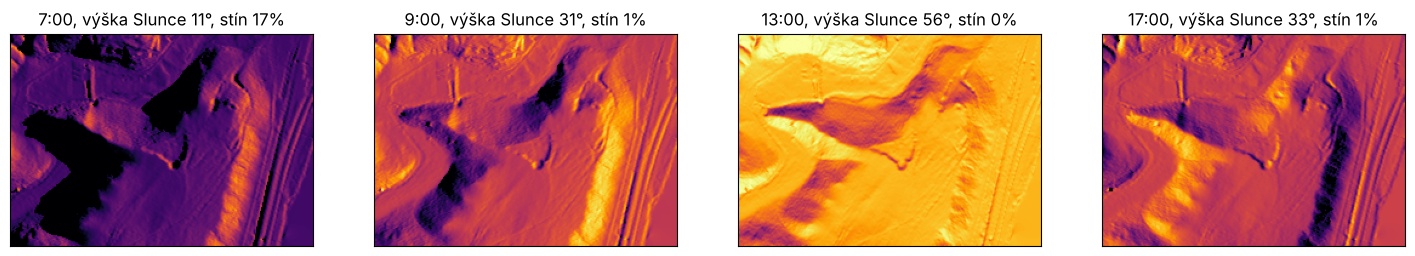

In [4]:
def sunpos(ts, lat, lon):
    """Zenitový úhel a azimut Slunce (rad; azimut od severu po směru hodin) pro časy v UTC, vzorce NOAA."""
    doy = ts.dayofyear.values; hr = ts.hour.values + ts.minute.values / 60
    g = 2 * np.pi / 365 * (doy - 1 + (hr - 12) / 24)
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g) - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    dec = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g) + 0.000907 * np.sin(2 * g)
           - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    ha = np.radians((hr * 60 + eqt + 4 * lon) / 4 - 180)
    phi = np.radians(lat)
    z = np.arccos(np.clip(np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec) * np.cos(ha), -1, 1))
    az = np.arctan2(np.sin(ha), np.cos(ha) * np.sin(phi) - np.tan(dec) * np.cos(phi)) + np.pi
    return z, np.mod(az, 2 * np.pi)

def shadow(z, az, dem=dmr, maxd=600):
    """Stín terénu: buňka je ve stínu, když nějaký terén ve směru Slunce leží nad paprskem."""
    if z >= np.pi / 2:
        return np.ones(dem.shape, bool)
    ii, jj = np.mgrid[0:dem.shape[0], 0:dem.shape[1]]
    sh = np.zeros(dem.shape, bool)
    for d in np.arange(RES, maxd, RES):
        i2 = np.round(ii - np.cos(az) * d / RES).astype(int); j2 = np.round(jj + np.sin(az) * d / RES).astype(int)
        ok = (i2 >= 0) & (i2 < dem.shape[0]) & (j2 >= 0) & (j2 < dem.shape[1])
        sh[ok] |= dem[i2[ok], j2[ok]] > dem[ok] + d / np.tan(z)
    return sh

hours = [7, 9, 13, 17]              # ◀ parametr: místní hodiny pro mapy
when = pd.DatetimeIndex([pd.Timestamp(f"{DAY} {h}:00").tz_localize("Europe/Prague").tz_convert("UTC").tz_localize(None) for h in hours])
zs, azs = sunpos(when, LAT, LON)
fig, ax = plt.subplots(1, len(hours), figsize=(4.5 * len(hours), 3.5))
for a, h, z, az in zip(ax, hours, zs, azs):
    cosi = np.cos(z) * np.cos(slope) + np.sin(z) * np.sin(slope) * np.cos(az - aspect)
    direct = np.clip(cosi, 0, None) * ~shadow(z, az)
    a.imshow(direct, cmap="inferno", vmin=0, vmax=1, extent=(0, W, 0, Hh)); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{h}:00, výška Slunce {90 - np.degrees(z):.0f}°, stín {shadow(z, az).mean():.0%}")
plt.show()

> **✏️ Úkol 1.** Které části území jsou v 7 hodin ve stínu a proč právě ty? Proč jsou ráno nejvíc osvětlené svahy obrácené k východu a v 17 hodin k západu, i když Slunce je v obou časech podobně vysoko? Co to znamená pro termosnímek údolí pořízený brzy ráno?

*Tvoje odpověď:* 

## 3. Teplota povrchu každé buňky

Pro každou buňku běží stejná energetická bilance jako v základní verzi, jen pohlcené záření je přímé záření krát cos i (mimo stín) plus rozptýlené záření krát podíl oblohy, který buňka vidí. Louka má půdu s vedením tepla do hloubky, les je tenká vrstva korun. Model běží od tří dní před vybraným dnem, výpočet trvá asi minutu.

výpočet 48 s, 175 × 250 buněk, 48 časů


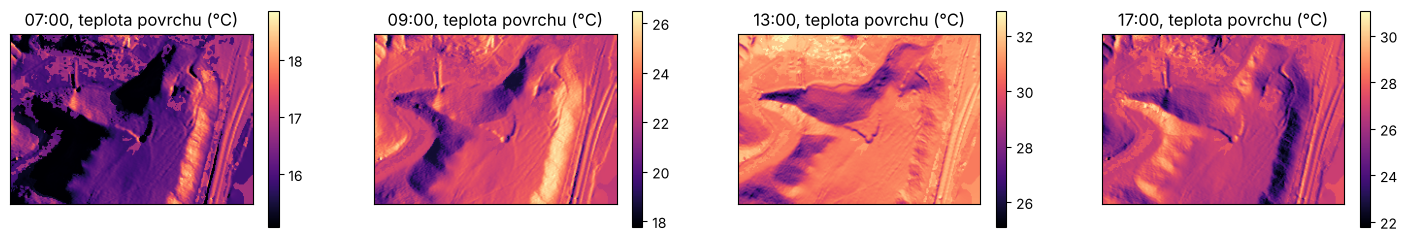

In [5]:
SIG = 5.670e-8
MEADOW = dict(alb=0.20, eps=0.98, k=1.2, C=2.5e6, rs=70.0)    # ◀ parametr: louka (albedo, emisivita, vodivost, kapacita půdy, odpor průduchů)
FOREST = dict(alb=0.12, eps=0.98, rs=100.0, node=3.0e4, rough=3.0)   # ◀ parametr: les (koruny jako jedna tenká vrstva)

def qsat(T):
    return 0.622 * 610.94 * np.exp(17.625 * (T - 273.15) / (T - 30.11)) / 101325

def run(day, terrain=True, dt=120, nl=12, depth=1.0):
    """Teplota povrchu každé buňky po půlhodinách dne day; model běží od tří dní předem."""
    ww = w[str(pd.Timestamp(day) - pd.Timedelta(days=3)): f"{day} 23:00"]
    t = (ww.index - ww.index[0]).total_seconds().values
    ts = np.arange(0, t[-1] + 3600, dt); times = ww.index[0] + pd.to_timedelta(ts, "s")
    Ta = np.interp(ts, t, ww.temperature_2m.values) + 273.15
    RH = np.interp(ts, t, ww.relative_humidity_2m.values) / 100
    DNI = np.interp(ts, t - 1800, ww.direct_normal_irradiance.values)    # záření je průměr za předchozí hodinu
    DHI = np.interp(ts, t - 1800, ww.diffuse_radiation.values)
    cc = np.interp(ts, t, ww.cloud_cover.values) / 100
    U = np.maximum(np.interp(ts, t, ww.wind_speed_10m.values) * 0.75, 0.3)
    e = RH * 610.94 * np.exp(17.625 * (Ta - 273.15) / (Ta - 30.11))
    Ld = (1.24 * (e / 100 / Ta) ** (1 / 7) * (1 - cc) + cc) * SIG * Ta ** 4
    qa = RH * qsat(Ta)
    zen, azi = sunpos(times, LAT, LON)
    f = forest.ravel(); n = f.size
    s_ = slope.ravel() if terrain else np.zeros(n); a_ = aspect.ravel()
    svf = (1 + np.cos(s_)) / 2                              # podíl oblohy, který buňka vidí
    alb = np.where(f, FOREST["alb"], MEADOW["alb"]); eps = np.where(f, FOREST["eps"], MEADOW["eps"])
    rs = np.where(f, FOREST["rs"], MEADOW["rs"]); rough = np.where(f, FOREST["rough"], 1.0)
    r = 1.0
    while 0.01 * (r ** nl - 1) / (r - 1 + 1e-12) < depth: r += 0.001
    dz = 0.01 * r ** np.arange(nl)
    cap = np.outer(np.full(n, MEADOW["C"]), dz); cap[f, 0] = FOREST["node"]; cap[f, 1:] = 1
    kk = np.outer(np.where(f, 0.0, MEADOW["k"]), 1 / ((dz[1:] + dz[:-1]) / 2))
    T = np.full((n, nl), Ta[: int(86400 / dt)].mean())
    rho, cp, L = 1.2, 1005, 2.45e6
    cache, outs, out_t = {}, [], []
    for i in range(len(ts)):
        sun = zen[i] < np.pi / 2
        if sun and terrain:
            key = int(ts[i] // 1200)                         # stín přepočítáme každých 20 min
            if key not in cache: cache = {key: shadow(zen[i], azi[i]).ravel()}
            lit = ~cache[key]
        else:
            lit = np.ones(n, bool)
        cosi = np.cos(zen[i]) * np.cos(s_) + np.sin(zen[i]) * np.sin(s_) * np.cos(azi[i] - a_)
        sw = DNI[i] * np.clip(cosi, 0, None) * lit * sun + DHI[i] * svf
        Ts = T[:, 0]; h = (5.7 + 3.8 * U[i]) * rough
        Rn = (1 - alb) * sw + eps * (Ld[i] * svf + (1 - svf) * SIG * Ta[i] ** 4 - SIG * Ts ** 4)
        H = h * (Ts - Ta[i]); LE = rho * L * (qsat(Ts) - qa[i]) / (rho * cp / h + rs)
        flux = kk * (T[:, :-1] - T[:, 1:])
        dT = np.zeros_like(T); dT[:, 0] = Rn - H - LE - flux[:, 0]; dT[:, 1:-1] = flux[:, :-1] - flux[:, 1:]; dT[:, -1] = flux[:, -1]
        T += dt * dT / cap
        if ts[i] % 1800 == 0 and times[i] >= pd.Timestamp(day):
            outs.append(T[:, 0].reshape(dmr.shape) - 273.15); out_t.append(times[i])
    return pd.DatetimeIndex(out_t).tz_localize("UTC").tz_convert("Europe/Prague"), np.array(outs)

t0 = time.time()
tt, TS = run(DAY)
print(f"výpočet {time.time() - t0:.0f} s, {TS.shape[1]} × {TS.shape[2]} buněk, {len(tt)} časů")
fig, ax = plt.subplots(1, len(hours), figsize=(4.5 * len(hours), 3.5))
for a, h in zip(ax, hours):
    k = int(np.argmin(np.abs(tt.hour + tt.minute / 60 - h)))
    im = a.imshow(TS[k], cmap="magma", extent=(0, W, 0, Hh)); fig.colorbar(im, ax=a, shrink=0.8); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{tt[k]:%H:%M}, teplota povrchu (°C)")
plt.show()

In [6]:
mead = ~forest & (np.degrees(slope) > 10)            # louky na svazích nad 10°
sector = pd.cut(np.degrees(aspect[mead]), [0, 45, 135, 225, 315, 360], labels=["S", "V", "J", "Z", "S2"]).astype(str)
sector = np.where(sector == "S2", "S", sector)
rows = {}
for h in [7, 9, 13, 17, 21]:
    k = int(np.argmin(np.abs(tt.hour + tt.minute / 60 - h)))
    rows[f"{h}:00"] = pd.Series(TS[k][mead]).groupby(sector).median()
tab = pd.DataFrame(rows).loc[["S", "V", "J", "Z"]]
tab.index = ["sever", "východ", "jih", "západ"]
print(f"louky na svazích nad 10°: {mead.sum()} buněk; medián teploty povrchu (°C) podle orientace svahu")
tab.round(1)

louky na svazích nad 10°: 1767 buněk; medián teploty povrchu (°C) podle orientace svahu


,7:00,9:00,13:00,17:00,21:00
sever,16.5,21.0,29.1,27.2,17.9
východ,17.5,24.0,31.7,26.0,17.5
jih,16.3,22.3,32.3,28.2,17.9
západ,16.2,19.9,30.1,29.0,18.0


> **✏️ Úkol 2.** O kolik stupňů se v 9 a ve 13 hodin liší louky na svazích obrácených k východu, jihu, západu a severu? Proč je ve 13 hodin nejteplejší jižní svah, ale v 17 hodin západní? Proč jsou rozdíly ve 21 hodin skoro pryč? Co by z toho plynulo pro hledání podmáčených míst na loukách podle teploty v poledne?

*Tvoje odpověď:* 

## 4. Kdy terén ruší nejméně

Rozptyl teploty mezi buňkami stejného povrchu (rozdíl 95. a 5. percentilu) ukazuje, jak velké rozdíly v termosnímku vytváří samotný terén, ne rozdíly v povrchu. Porovnáme nejslunečnější a nejzataženější den a sledujeme i rozdíl lesa a louky.

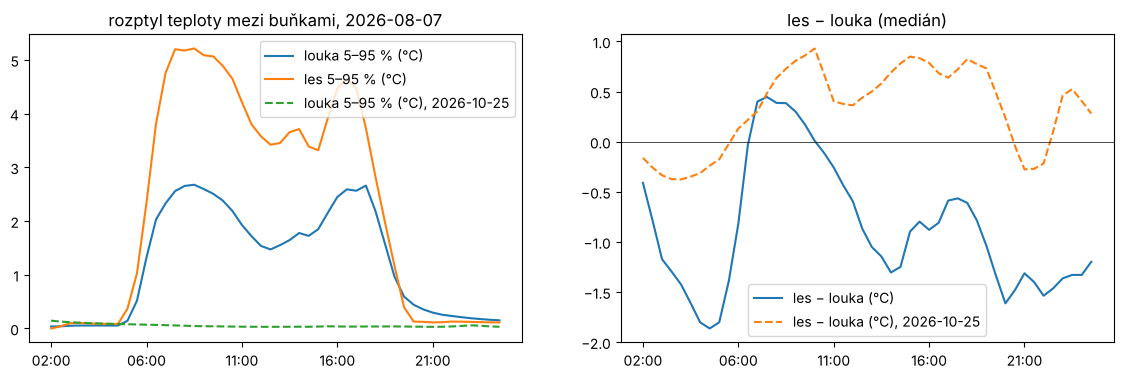

nejmenší rozptyl louky ve slunečný den: 02:00 (0.04 °C)
les a louka se ve slunečný den překříží kolem: ['07:30', '11:00']


In [7]:
def stats(tt, TS):
    m, f = ~forest, forest
    return pd.DataFrame({"louka 5–95 % (°C)": [np.percentile(x[m], 95) - np.percentile(x[m], 5) for x in TS],
                         "les 5–95 % (°C)": [np.percentile(x[f], 95) - np.percentile(x[f], 5) for x in TS],
                         "les − louka (°C)": [np.median(x[f]) - np.median(x[m]) for x in TS]}, index=tt.strftime("%H:%M"))
sun_day = stats(tt, TS)
tc, TC = run(CLOUDY)
cloud_day = stats(tc, TC)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sun_day[["louka 5–95 % (°C)", "les 5–95 % (°C)"]].plot(ax=ax[0], title=f"rozptyl teploty mezi buňkami, {DAY}")
cloud_day[["louka 5–95 % (°C)"]].rename(columns=lambda c: c + f", {CLOUDY}").plot(ax=ax[0], ls="--")
sun_day[["les − louka (°C)"]].plot(ax=ax[1], title="les − louka (medián)"); cloud_day[["les − louka (°C)"]].rename(columns=lambda c: c + f", {CLOUDY}").plot(ax=ax[1], ls="--")
ax[1].axhline(0, color="k", lw=0.5); plt.show()
print("nejmenší rozptyl louky ve slunečný den:", sun_day["louka 5–95 % (°C)"].idxmin(), f"({sun_day['louka 5–95 % (°C)'].min():.2f} °C)")
d = sun_day["les − louka (°C)"].values
print("les a louka se ve slunečný den překříží kolem:", [sun_day.index[i] for i in range(len(d) - 1) if np.sign(d[i]) != np.sign(d[i + 1])])

> **✏️ Úkol 3.** Ve kterou denní dobu je rozptyl teploty louky nejmenší a jak dlouho po západu Slunce trvá, než rozdíly mezi svahy zmizí? Proč nezmizí hned? Změň v `MEADOW` tepelnou vodivost `k` na 0,6 (suchá půda) a sleduj, jak se to změní. Jak velký je rozptyl v zataženém dni a proč?

*Tvoje odpověď:* 

> **✏️ Úkol 4.** Kdy se les a louka ve slunečném dni teplotně překříží a jak se to liší od zataženého dne? Model nepočítá se stékáním studeného vzduchu do údolí. Jak by skutečný termosnímek údolí před svítáním vypadal jinak než model a proč by pak nejmenší rozptyl nemusel být právě před svítáním?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Nastav `LAT, LON` na svah nad Brněnskou přehradou (49.2467, 16.4798) nebo na údolí u Hosína u Hluboké nad Vltavou (49.0452, 14.4769) a porovnej stíny, rozdíly podle orientace svahů a čas nejmenšího rozptylu.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Digitální model reliéfu ČR 5. generace (DMR 5G) a Digitální model povrchu ČR 1. generace (DMP 1G), © ČÚZK, licence CC BY 4.0, služby https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer a https://ags.cuzk.cz/arcgis2/rest/services/dmp1g/ImageServer
- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Poloha Slunce: NOAA Global Monitoring Laboratory, *General Solar Position Calculations* (vzorce pro deklinaci a časovou rovnici).
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744.
- Oke, T. R. (1987). *Boundary Layer Climates*, 2. vyd. Routledge (tepelné vlastnosti půdy, albeda, místní klima svahů).
- Maes, W. H. (2025). Practical guidelines for performing UAV mapping flights with snapshot sensors. *Remote Sensing* 17(4), 606. https://doi.org/10.3390/rs17040606

### Jak citovat

OpenSkyLab (2026). Kdy letět s termokamerou, pokročilá verze: svahy, stíny a les na skutečném terénu [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/thermal_timing_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*